In [147]:
# Let's import first the relevant packages that we will need in this tutorial
import numpy as np
import matplotlib.pyplot as plt

from scipy.sparse import csr_matrix, diags # used to store and process sparse matrices (compressed sparse row matrix)
from sklearn.decomposition import PCA # we will benchmark diffusion maps against pca
from sklearn.neighbors import NearestNeighbors # we will use this to implement KNN
from scipy.sparse.linalg import eigs # we need this to calculate the eigenspectrum of the transition matrix

from scipy.spatial.distance import pdist, squareform # to calculate distances between pairs of points

# Archimedean Spiral

$$
r(\theta)=a+b\theta,
\qquad
x(\theta)=r(\theta)\cos\theta,
\qquad
y(\theta)=r(\theta)\sin\theta,
$$

Here, we assume that $b>0$ and sample equally spaced angles $\theta$ over $[0,3.1\pi]$.

### Let's first derive the arc-length element

For a small infinitesimal displacement along a curve,

$$
ds=\sqrt{dx^2+dy^2}
$$

Therefore,

$$
\frac{ds}{d\theta}
=
\sqrt{
\left(\frac{dx}{d\theta}\right)^2
+
\left(\frac{dy}{d\theta}\right)^2
}
$$

Since $dr/d\theta=b$,

$$
\frac{dx}{d\theta}=\frac{\partial x}{\partial r}\frac{dr}{d\theta}+\frac{\partial x}{\partial \theta}=b\cos\theta-r\sin\theta,
\qquad
\frac{dy}{d\theta}=\frac{\partial y}{\partial r}\frac{dr}{d\theta}+\frac{\partial y}{\partial \theta}=b\sin\theta+r\cos\theta
$$

Let's square and add these two terms,

$$
\begin{aligned}
\left(\frac{dx}{d\theta}\right)^2
+
\left(\frac{dy}{d\theta}\right)^2
&=
(b\cos\theta-r\sin\theta)^2
+
(b\sin\theta+r\cos\theta)^2
\\
&=
b^2(\cos^2\theta+\sin^2\theta)
+
r^2(\sin^2\theta+\cos^2\theta)
\\
&=b^2+r^2,
\end{aligned}
$$

since the cross terms cancel. Thus,

$$
\frac{ds}{d\theta}
=
\sqrt{r^2+b^2}
=\sqrt{(a+b\theta)^2+b^2}
\tag{1}\label{eq:ds/dtheta}
$$

Geometrically, increasing $\theta$ produces both a radial displacement
$b\,d\theta$ and a tangential displacement $r\,d\theta$.
Since both these displacements are perpendicular, their lengths combine using the Pythagorean theorem.

### Let us now integrate $ds/d\theta$ to obtain the arc length

The distance along the spiral from $\theta^{'}=0$ to $\theta^{'}=\theta$ is

$$
s(\theta)
=
\int_0^\theta \sqrt{(a+b\theta^{'})^2+b^2}\,d\theta^{'}
$$

Substitute

$$
R=a+b\theta^{'},
\qquad
d\theta^{'}=\frac{dR}{b}
$$

The integration limits become $R=a$ and $R=a+b\theta$, giving

$$
s(\theta)
=
\frac{1}{b}
\int_a^{a+b\theta} \sqrt{R^2+b^2}\,dR
$$

Recall that for a constant $c$,
$$
\int\sqrt{x^2+c^2}dx=\frac{1}{2}x\sqrt{x^2+c^2}+\frac{c^2}{2}\ln{\bigg|x+\sqrt{x^2+c^2}\bigg|}+C
$$

Here, $C$ is the constant of integration. Now, we define 
$$
F(R, b)=
\frac{1}{2b}
\left[
R\sqrt{R^2+b^2}
+
b^2\ln\left|R+\sqrt{R^2+b^2}\right|
\right],
\qquad b\neq 0
$$
Thus, we can write the arc length as 
$$
s(\theta)=F(a+b\theta, b)-F(a, b)
$$

##### We generate our spiral using $N_{\text{samples}}=1000$ corresponding to $1000$ values of equally spaced angles over $[0,3.1\pi]$.

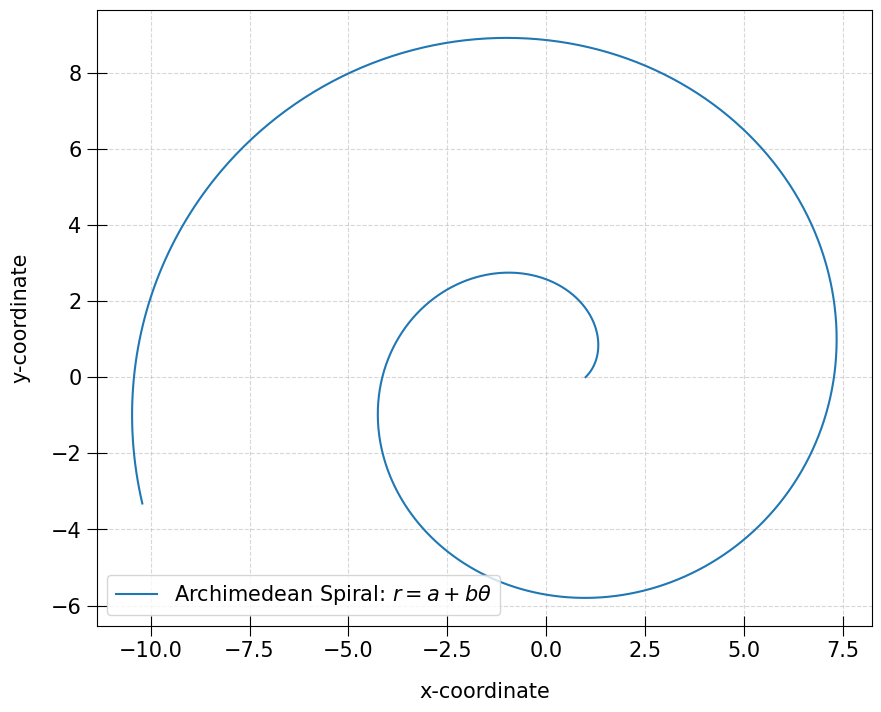

In [184]:
# we define here our hyperparameters to generate our spiral

n_samples = 1000
a = 1.0
b = 1.0
thetas = np.linspace(0.0, 3.1 * np.pi, n_samples)

rs = a + b * thetas
X = np.column_stack([rs * np.cos(thetas), rs * np.sin(thetas)])

#Let us plot this spiral
plt.subplots(figsize=(10,8), dpi=100)
plt.plot(X[:, 0], X[:, 1], label="Archimedean Spiral: $r=a+b\\theta$")
plt.xlabel("x-coordinate", fontsize=15, labelpad=15)
plt.ylabel("y-coordinate", fontsize=15, labelpad=15)
plt.tick_params(axis="both", size=15, labelsize=15, direction="inout")
plt.legend(fontsize=15)
plt.grid(alpha=0.5, ls="--")

In [185]:
# Function for arc length
def F(R, b):
    return (1 / (2 * b)) * (R * np.sqrt(R ** 2 + b ** 2) + b ** 2 * (np.log(np.abs(R + np.sqrt(R ** 2 + b ** 2)))))

s = F(a + b * thetas, b) - F(a, b)

# We scale the arc length to [0.0, 1.0] by using (s-min(s))/(max(s)-min(s))
s_scaled = (s - np.min(s)) / (np.max(s) - np.min(s))

# Noisy Dataset
We want to test robustness of either PCAs or Diffusion maps against noise. So, let's add Gaussian noise to this spiral with mean $\mu=0.0$ and standard deviation $\sigma=1.0$

$$
x\to x+\mathcal{N}(\mu,\sigma^2),
\qquad y\to y+\mathcal{N}(\mu,\sigma^2)
$$

Let $\vec{s}$ be the column vector represent the true arc lengths corresponding to equally spaced $\vec{\theta}$ over $[0,3.1\pi]$. We now scale the arc length as follows such that it lies in $[0.0,1.0]$ 

$$
\tilde{s}(\theta_i)=\frac{s(\theta_i)-\max{(\vec{s})}}{\min{(\vec{s})}-\max{(\vec{s})}}
$$

for $i=1,2,\cdots,N_{\text{samples}}$. 

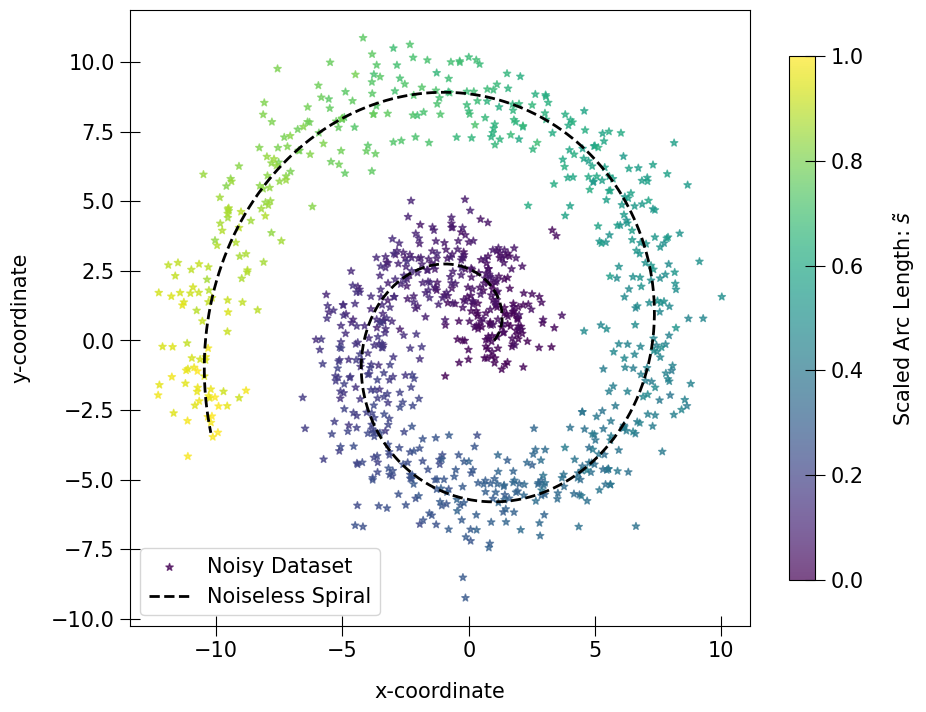

In [186]:
mu = 0.0
sigma = 1.0

seed = 42 # for reproducibility
rng = np.random.default_rng(seed)

X_noise = X + rng.normal(loc=mu, scale=sigma, size=X.shape) # normal noise added



#Let us plot this spiral
plt.subplots(figsize=(10,8), dpi=100)
scatter = plt.scatter(X_noise[:, 0], X_noise[:, 1], c=s_scaled, cmap="viridis", s=30, alpha=0.70, label="Noisy Dataset", marker="*")
plt.plot(X[:, 0], X[:, 1], color="black", linestyle="--", linewidth=2, label="Noiseless Spiral")
plt.xlabel("x-coordinate", fontsize=15, labelpad=15)
plt.ylabel("y-coordinate", fontsize=15, labelpad=15)
plt.tick_params(axis="both", size=15, labelsize=15, direction="inout")
plt.legend(fontsize=15)

cbar = plt.colorbar(scatter, shrink=0.85)
cbar.set_label(r"Scaled Arc Length: $\tilde{s}$", fontsize=15, labelpad=20)
cbar.ax.tick_params(labelsize=15, direction="inout", size=15)


# Principle Component Analysis (PCA)

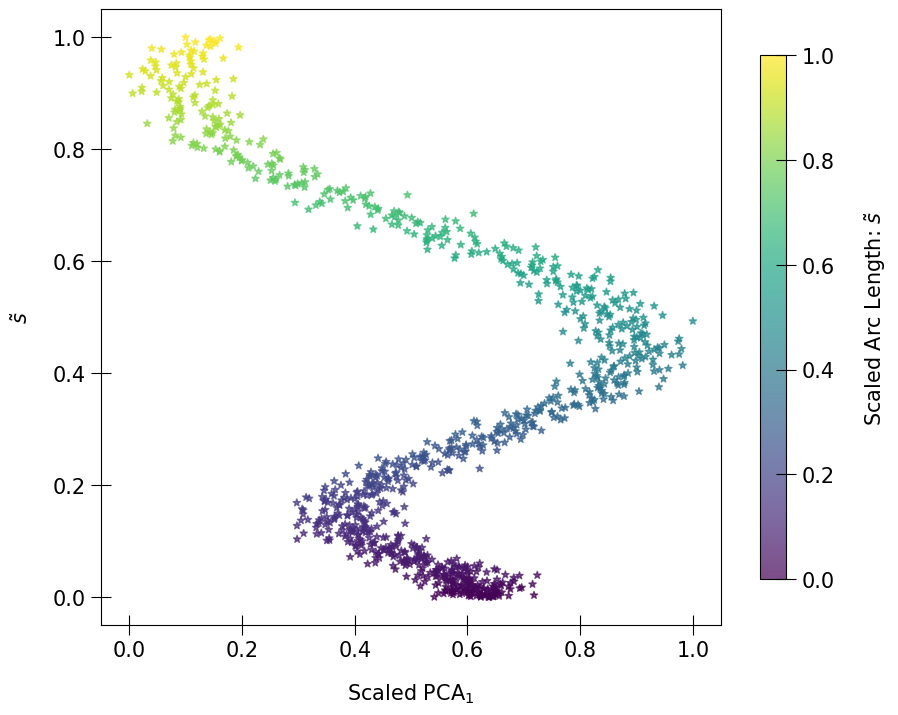

In [187]:
pca = PCA(n_components=2)
pca_coordinates = pca.fit_transform(X_noise)
pca1 = pca_coordinates[:, 0]
pca2 = pca_coordinates[:, 1]

#Let's also scale the PCA1 coordinate
pca1_scaled = (pca1 - pca1.min()) / (pca1.max() - pca1.min())

plt.subplots(figsize=(10,8), dpi=100)
scatter = plt.scatter(pca1_scaled, s_scaled, c=s_scaled, cmap="viridis", s=30, alpha=0.70, marker="*")
plt.xlabel("Scaled $\\text{PCA}_1$", fontsize=15, labelpad=15)
plt.ylabel("$\\tilde{s}$", fontsize=15, labelpad=15)
plt.tick_params(axis="both", size=15, labelsize=15, direction="inout")

cbar = plt.colorbar(scatter, shrink=0.85)
cbar.set_label(r"Scaled Arc Length: $\tilde{s}$", fontsize=15, labelpad=20)
cbar.ax.tick_params(labelsize=15, direction="inout", size=15)

Thus, we establish that the first PCA coordinate is not a monotonically increasing function of the spiral's arc length. This is the result I told you in lecture 1 that we wanted to reproduce in Fig.1 (b) of the paper: [Exploiting Low-Dimensional Structure in Astronomical Spectra
](https://arxiv.org/abs/0807.2900)
Instead, we will do this for a more complicated shape: Swiss roll

## Swiss Roll

A Swiss roll is a two-dimensional sheet embedded in three dimensions. We construct it by drawing an Archimedean spiral in the $xy$-plane and extending it vertically. The two coordinates that locate a point on this sheet are the angle $\theta$ along the spiral and the height $h$. For this calculation, we set $a=0$ and $b=1$ which gives that $r(\theta)=\theta$, so the usual polar-coordinate equations are

$$
x=\theta\cos\theta,
\qquad
y=\theta\sin\theta
$$

Adding the vertical coordinate $z=h$ gives the Swiss-roll surface $(\theta\cos{\theta}, \theta\sin{\theta}, h)$. Let

$$
\frac{3\pi}{2}\leq \theta\leq \frac{9\pi}{2}
\quad
0\le h\le H
$$

At fixed $h$, increasing $\theta$ traces the spiral from its inner edge to its outer edge. The angle increases by $3\pi$, so the sheet makes $1.5$ turns. At fixed $\theta$, increasing $h$ traces a vertical straight line. 


### Let's look at the arc-length element 

Let $s$ be the distance traveled along the spiral from its inner edge $\theta$ to angle $\theta$, keeping $h$ fixed. Using Eqn. \eqref{eq:ds/dtheta}, we get $ds/d\theta=\sqrt{1+\theta^2}$ (since $a=0$, $b=1$). Integrating this like before, we can write the arc length as 
$$
s(\theta)=F(\theta, 1)-F(1.5\pi, 1)
$$

such that $s(\theta=1.5\pi)=0$ i.e. the inner edge starts with $0$ arc length. We choose the total length of the spiral $L$ and the height $H$ such that 

$$
L=s(4.5\pi),
\qquad
H=\frac{L}{2.4}.
$$

Here, we are taking the unrolled sheet with a length-to-height ratio of $2.4$, where $2.4$ is just a number you can change. The coordinates $(s,h)$ therefore unroll the Swiss roll into the rectangle $[0,L]\times[0,H]$. The shortest distance **along the sheet** between two sampled points $i$ and $j$ is the straight-line distance in the unrolled rectangle:

$$
d_{\mathrm{sheet}}(i,j)
=
\sqrt{(s_i-s_j)^2+(h_i-h_j)^2}.
$$

Since two points on adjacent turns can be close in three-dimensional space even when this distance along the sheet is large.

### Sampling

Sampling will not necessarily be uniform **along the sheet**. There can be a significant density variation. 

Let us see the issue in this sampling. Notice that a small patch with angular width $d\theta$ and height $dh$ has surface area

$$
dA=ds\,dh=\sqrt{1+\theta^2}\,d\theta\,dh
$$

For the same $d\theta$ and $dh$, a patch near the outer edge has more area than a patch near the inner edge. Sampling $\theta$ uniformly would make the inner edge more densely sampled. To give equal-area patches the same expected number of points, we sample independently and uniformly on the unrolled rectangle:

$$
s_i\sim\mathrm{Uniform}(0,L),
\qquad
h_i\sim\mathrm{Uniform}(0,H)
$$

Equivalently, one could sample $\theta$ directly using the probability density

$$
p_\Theta(\theta)
=p_S(s)\left|\frac{ds}{d\theta}\right|
=\frac{1}{L}\frac{ds}{d\theta}
=\frac{\sqrt{1+\theta^2}}{L}
\qquad \frac{3\pi}{2}\le\theta\le\frac{9\pi}{2}
$$

Sampling $\theta$ uniformly gives equal-angle strips the same expected number of points. The outer strip spreads those points over a wider area and, as a result, looks more sparsely sampled. The above sampling technique (sampling $s$ uniformly) assigns more samples per unit angle to the longer outer turns, giving the same expected number of samples per unit surface area everywhere. 

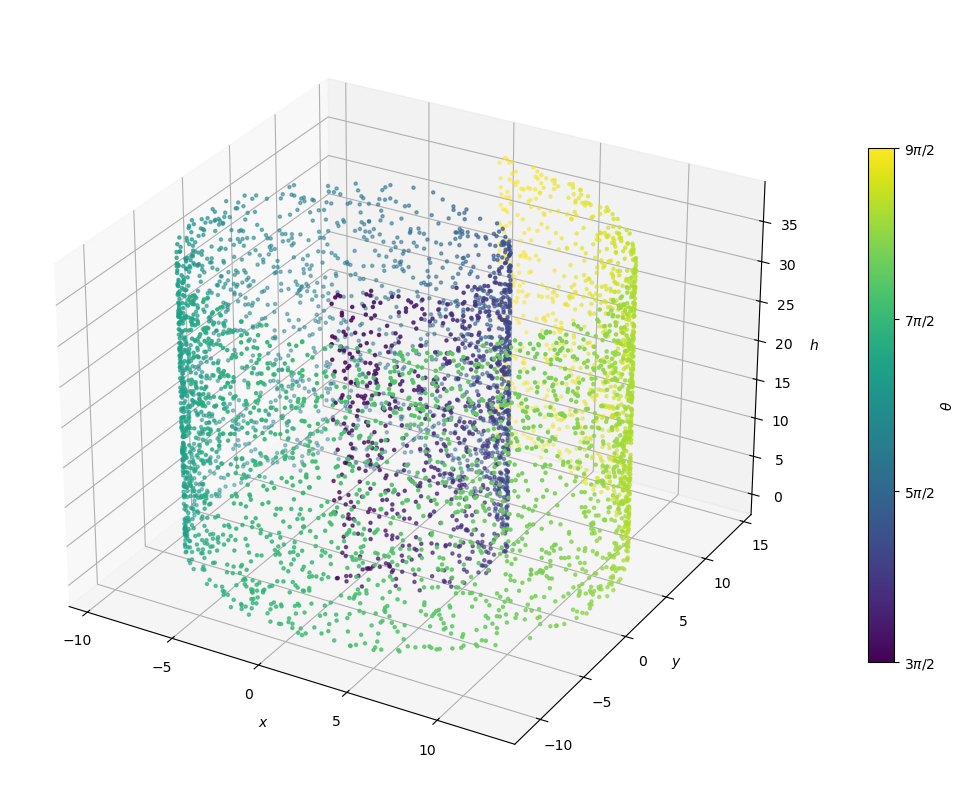

In [188]:
# Parameters for our Swiss roll
n_samples = 5000
a = 0
b = 1.0
theta_min = 3 * np.pi / 2
theta_max = 9 * np.pi / 2
L = F(a + b * theta_max, b) - F(a + b * theta_min, b)
H = L / 2.4

# We implement here rejection sampling
rng = np.random.default_rng(42)
thetas = np.empty(n_samples)
n_filled = 0

while n_filled < n_samples:
    n_needed = n_samples - n_filled
    candidates = rng.uniform(theta_min, theta_max, size=n_needed)
    prob = np.sqrt(1 + candidates ** 2) / np.sqrt(1 + theta_max ** 2)
    accepted = candidates[rng.random(n_needed) < prob]
    thetas[n_filled:n_filled + accepted.size] = accepted
    n_filled += accepted.size

hs = rng.uniform(0, H, size=n_samples)
xs = thetas * np.cos(thetas)
ys = thetas * np.sin(thetas)
zs = hs

# We plot here
fig = plt.figure(figsize=(10, 8), layout="constrained")
ax = fig.add_subplot(projection="3d")
points = ax.scatter(xs, ys, zs, c=thetas, cmap="viridis", s=5, vmin=theta_min, vmax=theta_max)
ax.set(xlabel="$x$", ylabel="$y$", zlabel="$h$")
ax.view_init(elev=28, azim=-60)
cbar = fig.colorbar(points, ax=ax, shrink=0.65, pad=0.08)
cbar.set_label(r"$\theta$")
cbar.set_ticks(np.pi * np.array([1.5, 2.5, 3.5, 4.5]), labels=["$3\pi/2$", "$5\pi/2$", "$7\pi/2$", "$9\pi/2$"])
plt.show()

# Principle Component Analysis (PCA)

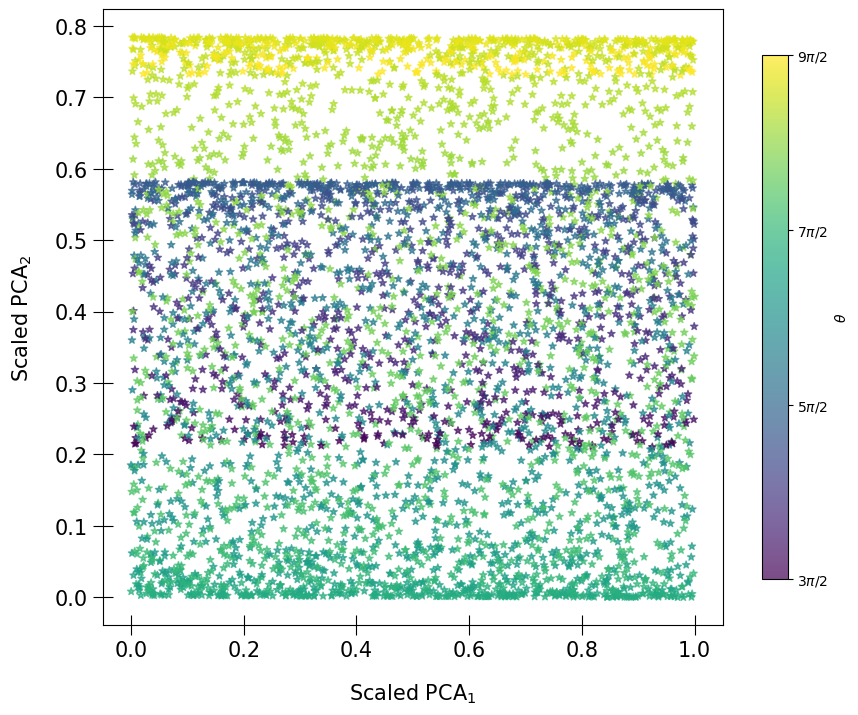

In [40]:
X = np.column_stack([xs, ys, zs])
pca = PCA(n_components=2)
pca_coordinates = pca.fit_transform(X)
pca1 = pca_coordinates[:, 0]
pca2 = pca_coordinates[:, 1]

#Let's also scale the PCA1 and PCA2 coordinates
pca1_scaled = (pca1 - pca1.min()) / (pca1.max() - pca1.min())
pca2_scaled = (pca2 - pca2.min()) / (pca2.max() - pca1.min())
plt.subplots(figsize=(10,8), dpi=100)
scatter = plt.scatter(pca1_scaled, pca2_scaled, c=thetas, cmap="viridis", s=30, alpha=0.70, marker="*")
plt.xlabel("Scaled $\\text{PCA}_1$", fontsize=15, labelpad=15)
plt.ylabel("Scaled $\\text{PCA}_2$", fontsize=15, labelpad=15)
plt.tick_params(axis="both", size=15, labelsize=15, direction="inout")
cbar = plt.colorbar(scatter, shrink=0.85)
cbar.set_label(r"$\theta$")
cbar.set_ticks(np.pi * np.array([1.5, 2.5, 3.5, 4.5]), labels=["$3\pi/2$", "$5\pi/2$", "$7\pi/2$", "$9\pi/2$"])

In [49]:
k = 24
dist, ind = NearestNeighbors(n_neighbors=k).fit(X).kneighbors()

### Choosing the kernel bandwidth $\epsilon$

In the diffusion map, a point $i$ assigns each neighbor $j$ a Gaussian weight

$$
W_{ij}=\exp\!\left(-\frac{d_{ij}^2}{\epsilon}\right)
$$

where $d_{ij}$ is the distance metric between the two points in $(x,y,z)$ space. The parameter $\epsilon$ controls how quickly the weight decreases with distance.

We choose `epsilon = np.median(dist[:, -1])**2`. Each row `dist[i]` contains the distances from point $i$ to its $k=24$ nearest neighbors, sorted from smallest to largest. Its last entry, `dist[i, -1]`, is therefore the radius needed to reach the 24th neighbor. Denote this radius by $r_i$. Taking the median over all points gives a typical neighborhood radius,

$$
r_{\mathrm{typ}}=\operatorname{median}(r_1,\ldots,r_N).
$$

We set $\epsilon=r_{\mathrm{typ}}^2$ because the Gaussian kernel uses squared distance. With this choice,

$$
W_{ij}=\exp\!\left[-\left(\frac{d_{ij}}{r_{\mathrm{typ}}}\right)^2\right]
$$

For example, a neighbor at half the typical radius receives weight $e^{-1/4}\approx 0.78$, while a neighbor at the typical radius receives weight $e^{-1}\approx 0.37$. Thus, closer neighbors contribute more strongly, and points near the edge of a typical neighborhood still contribute appreciably.

In [81]:
epsilon = np.median(dist[:, -1]) ** 2
rows = np.repeat(np.arange(n_samples), k)
cols = ind.ravel()
weights = np.exp(-dist.ravel() ** 2 / epsilon)
W = csr_matrix((weights, (rows, cols)), shape=(n_samples, n_samples))
W = W.maximum(W.T) # this step makes the W symmetric. say for example: W[0,1]=0.78 and W[1,0]=0, it compares the max which is 0.78. 
W.setdiag(1.0)

### Density correction in diffusion maps:

Suppose we instead sampled the Swiss roll uniformly in angle $\theta$ and height $h$. The inner turns then contain more points per unit surface area than the outer turns. If our goal is to recover the geometry of the sheet, we want a comparable influence for two equidistance equal-area patches. Imagine a walker at point $i$ with two small patches, $A$ and $B$, nearby. Suppose the patches have equal area and are equally far from $i$. Patch $A$ contains 20 sampled points and patch $B$ contains 10. The walker is twice as likely to enter $A$ simply because there are twice as many sampled points there. For each point $j$, define its total neighborhood weight

$$
q_j=\sum_\ell W_{j\ell}
$$

So, we divide by $q_j$. Patch $A$ still contains twice as many points, but each now contributes half as much. But, diffusion maps use the symmetric corrected kernel

$$
K_{ij}=\frac{W_{ij}}{q_iq_j}
$$

The two factors play distinct roles. For a walk starting at $i$, the destination factor $1/q_j$ changes the relative weights of its neighbors. The source factor $1/q_i$ is common to the entire row. Including it makes the correction symmetric, so $K_{ij}=K_{ji}$.

We can see exactly what survives when we turn $K$ into transition probabilities:

$$
P_{ij}
=\frac{K_{ij}}{\sum_\ell K_{i\ell}}
=\frac{W_{ij}/(q_iq_j)}
       {\sum_\ell W_{i\ell}/(q_iq_\ell)}
=\frac{W_{ij}/q_j}{\sum_\ell W_{i\ell}/q_\ell}
$$

The source factor cancels. For a walker at $i$, each destination $j$ therefore receives its original similarity weight $W_{ij}$ multiplied by its inverse local-density estimate $1/q_j$. This is the diffusion-map normalization.

If we sample uniformly in arc length $s$ and height $h$, the surface sampling density is already uniform. We do not have to worry about that here. 


In [114]:
q = np.asarray(W.sum(axis=1)).ravel() #axis=1: row-wise total, but the dtype is a matrix and hence asarray and then flatten
Q = diags(1 / q)
K = Q @ W @ Q # density correction
d = np.asarray(K.sum(axis=1)).ravel()
P = diags(1/d) @ K

Each entry $P_{ij}\geq 0$ is the probability of moving from point $i$ to point $j$ in one step. Since each row is a probability distribution,

$$
\sum_{j=1}^{N}P_{ij}=1
\qquad \text{for every } i
$$

The constant vector is a right eigenvector with eigenvalue 1. Let $\mathbf{1}=(1,\ldots,1)^T$. The $i$th component of $P\mathbf{1}$ is

$$
(P\mathbf{1})_i=\sum_{j=1}^{n}P_{ij}\cdot 1=1
$$

Therefore $P\mathbf{1}=\mathbf{1}$, so $\lambda=1$ is an eigenvalue. Let's prove now that every eigenvalue satisfies $|\lambda|\leq 1$. Let $Pv=\lambda v$ with $v\neq 0$. Choose an index $i$ where $|v_i|$ is maximal, so $|v_j|\leq |v_i|$ for every $j$. Using the eigenvalue equation in row $i$ gives

$$
|\lambda|\,|v_i|
=\left|\sum_j P_{ij}v_j\right|
\leq \sum_j P_{ij}|v_j|
\leq \sum_j P_{ij}|v_i|
=|v_i|
$$

This gives $|\lambda|\leq 1$. 

### Diffusion distance and diffusion coordinates

$P_{ij}$ is the probability of moving from point $i$ to point $j$ in one step. After $t$ steps, $(P^t)_{ij}$ is the probability of reaching $j$ from $i$. The diffusion distance between points $i$ and $j$ compares where two walkers starting at those points are likely to end up:

$$
D_t^2(i,j)
\propto
\sum_{\ell=1}^{N}
\big[(P^t)_{i\ell}-(P^t)_{j\ell}\big]^2
$$
The diffusion coordinates come from the right eigenvectors $P\psi_m=\lambda_m\psi_m$. After skipping the constant mode ($\lambda_0=1$), the first $M$ coordinates of point $i$ are

$$
\Phi_t(i)=
\big(\lambda_1^t\psi_1(i),\ldots,\lambda_M^t\psi_M(i)\big).
$$

In [115]:
#calculate eigenvalues and eigenvectors of the 5 largest real-part eigenvalues.
lam, psi = eigs(P, k=5, which="LM", v0=np.random.default_rng(11).normal(size=n_samples)) 
# find sorted indices of eigenvalues from smallest to largest, then [::-1] reverses that order and [1:] excludes the eigenvalue 1
order = np.argsort(lam)[::-1][1:]
lam, psi = lam[order].real, psi[:, order].real
# we set diffusion time here as 1
dc = psi * lam
# scale dc coordinates
dc_min = dc.min(axis=0)
dc_max = dc.max(axis=0)
dc_scaled = (dc - dc_min) / (dc_max - dc_min)

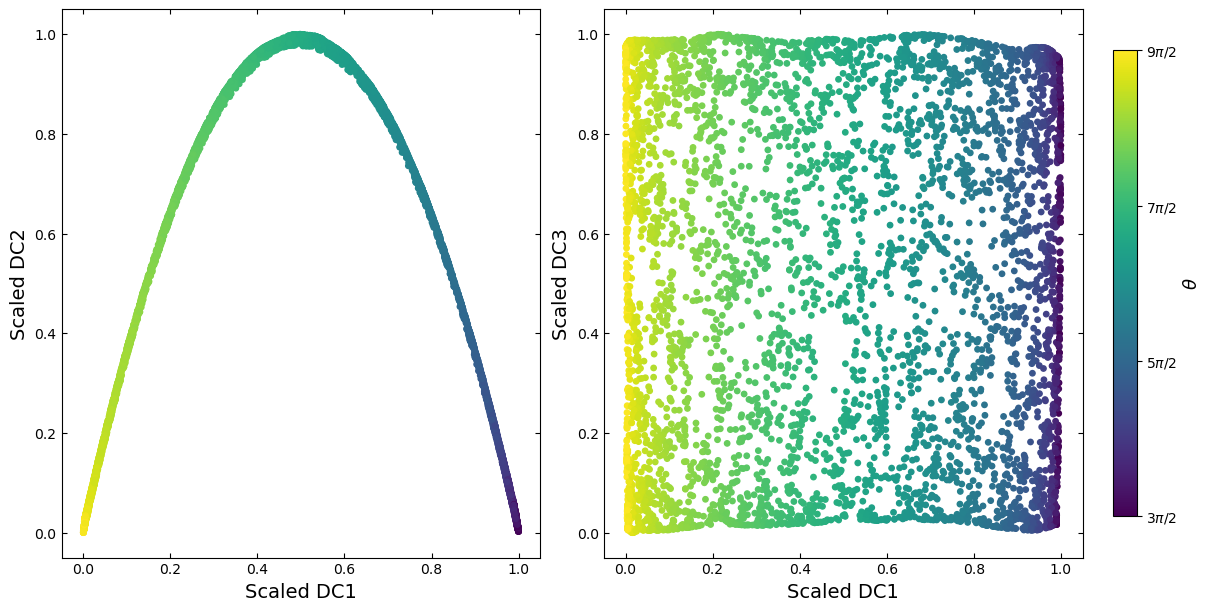

In [116]:

fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharex=True, layout="constrained")

for ax, col in zip(axes, [1, 2]):
    scatter = ax.scatter(dc_scaled[:, 0], dc_scaled[:, col], c=thetas, cmap="viridis", vmin=theta_min, vmax=theta_max, s=15)
    ax.set_xlabel("Scaled DC1", fontsize=14)
    ax.set_ylabel(f"Scaled DC{col + 1}", fontsize=14)
    ax.tick_params(direction="in", top=True, right=True)

cbar = fig.colorbar(scatter, ax=axes, shrink=0.85, pad=0.03)
cbar.set_label("$\\theta$", fontsize=13)
cbar.set_ticks(np.pi * np.array([1.5, 2.5, 3.5, 4.5]), labels=["$3\pi/2$", "$5\pi/2$", "$7\pi/2$", "$9\pi/2$"])
plt.show()

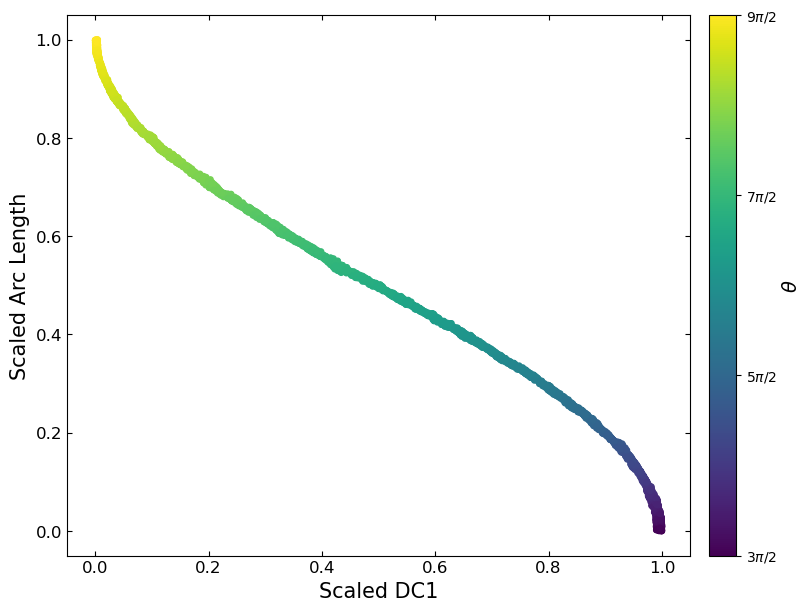

In [123]:
s = F(a + b * thetas, b) - F(a + b * theta_min, b)
s_scaled = (s - s.min())/ (s.max() - s.min())
fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")

scatter = ax.scatter(dc_scaled[:, 0], s_scaled, c=thetas, cmap="viridis", vmin=theta_min, vmax=theta_max, s=15)
ax.set_xlabel("Scaled DC1", fontsize=15)
ax.set_ylabel("Scaled Arc Length", fontsize=15)
ax.tick_params(direction="in", top=True, right=True, labelsize=12)

cbar = fig.colorbar(scatter, ax=ax, pad=0.03)
cbar.set_label("$\\theta$", fontsize=14)
cbar.set_ticks(np.pi * np.array([1.5, 2.5, 3.5, 4.5]), labels=["$3\pi/2$", "$5\pi/2$", "$7\pi/2$", "$9\pi/2$"])
plt.show()

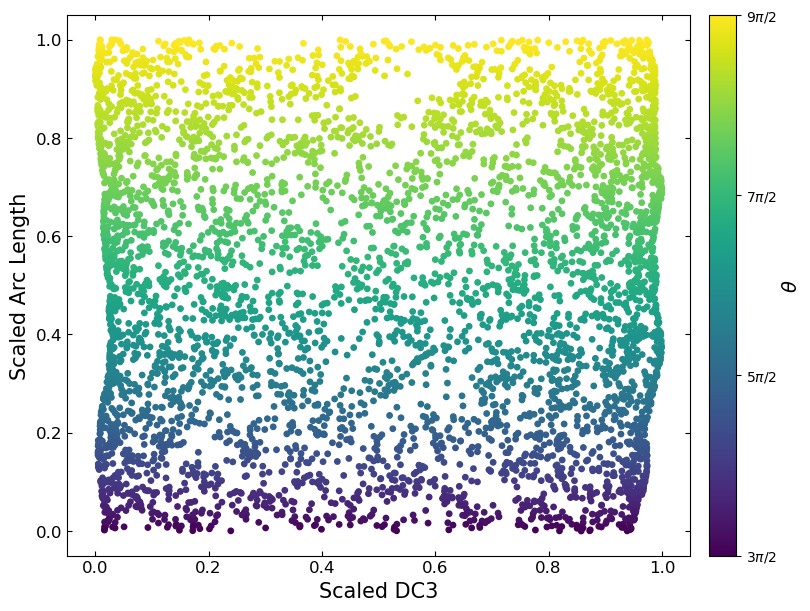

In [124]:
s = F(a + b * thetas, b) - F(a + b * theta_min, b)
s_scaled = (s - s.min())/ (s.max() - s.min())
fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")

scatter = ax.scatter(dc_scaled[:, 2], s_scaled, c=thetas, cmap="viridis", vmin=theta_min, vmax=theta_max, s=15)
ax.set_xlabel("Scaled DC3", fontsize=15)
ax.set_ylabel("Scaled Arc Length", fontsize=15)
ax.tick_params(direction="in", top=True, right=True, labelsize=12)

cbar = fig.colorbar(scatter, ax=ax, pad=0.03)
cbar.set_label("$\\theta$", fontsize=14)
cbar.set_ticks(np.pi * np.array([1.5, 2.5, 3.5, 4.5]), labels=["$3\pi/2$", "$5\pi/2$", "$7\pi/2$", "$9\pi/2$"])
plt.show()

## HW: Add noise to this dataset and see if diffusion maps work!

## Practical Application: Qi-Wu-Zhang Model

The Qi–Wu–Zhang (QWZ) model describes a two-dimensional lattice with two internal states per unit cell. Its Hamiltonian at crystal momentum $\mathbf{k}=(k_x,k_y)$ is

$$
H(\mathbf{k};\mu)
=
\mathbf{d}(\mathbf{k};\mu)\cdot\boldsymbol{\sigma}
=
d_x\sigma_x+d_y\sigma_y+d_z\sigma_z,
$$

where $\sigma_x,\sigma_y,\sigma_z$ are Pauli matrices acting on the two internal states. The components are

$$
\begin{aligned}
d_x &= \sin k_x,\\
d_y &= \sin k_y,\\
d_z &= \mu-2b\left(2-\cos k_x-\cos k_y\right).
\end{aligned}
$$

Here $b>0$ sets the hopping scale, $\mu$ is the chemical potential, and $(k_x,k_y)\in[-\pi,\pi]^2$ covers the Brillouin zone. In matrix form,

$$
H(\mathbf{k};\mu)
=
\begin{pmatrix}
d_z & d_x-i d_y\\
d_x+i d_y & -d_z
\end{pmatrix}.
$$

This system has 4 phases. Hence, using diffusion maps, we need to identify 4 clusters. 
We reproduce here the results of the paper: [Topological quantum phase transitions retrieved through unsupervised machine
learning](https://arxiv.org/abs/2002.02363)

To produce this dataset, we sample $M=800$ $\mu$ from $-4b$ to $12b$, where $b$ is set to $0.2$. We chop the momentum grid $(k_x,k_y)$ into $N\times N$ intervals where $N=32$ is taken in the paper. Thus, this gives us $33\times 33=1089$ grid points. 
We then compute the Bloch vector $(d_x(k_{ij}), d_y(k_{ij}), d_z(k_{ij}))$ at every grid point $(i,j)$ and normalize it. Since there are $1089$ grid points and three Bloch components per grid point, this gives us a total of $33\times 33\times 3$ Bloch components per value of chemical potential $\mu$. We flatten this to get $3267$ features. Thus, we have a dataset of size $800\times 3267$.
### Chebyshev vs. Euclidean distance

For two such data points $\mathbf{x},\mathbf{y}\in\mathbb{R}^{3267}$,

$$
d_{\infty}(\mathbf{x},\mathbf{y})
= \max_{1\leq i\leq 3267}|x_i-y_i|,
\qquad
d_2(\mathbf{x},\mathbf{y})
= \sqrt{\sum_{i=1}^{3267}(x_i-y_i)^2}
$$

**Chebyshev distance** measures the largest change in any single component.
**Euclidean distance** combines changes across all components, so many small
changes can contribute as much as one large change.

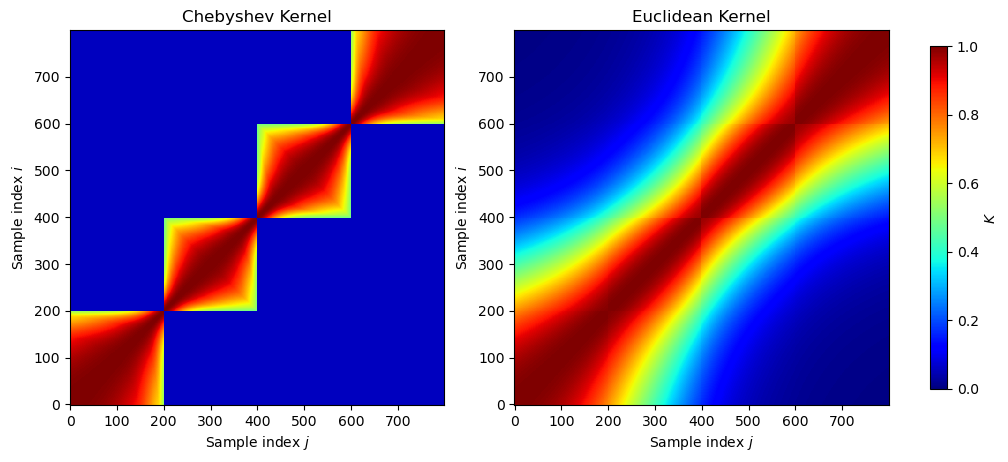

In [165]:
b = 0.2 # hopping scale in the paper
N = 32  
M = 800 # Number of chemical potentials
epsilon_cheb = 0.345
epsilon_eucl = 1.28e-4

mu = np.linspace(-4 * b, 12 * b, M) #in the paper, they sample mu from -0.8 to 2.4 in 800 mu steps.
k = np.linspace(-np.pi, np.pi, N + 1)
kx, ky = np.meshgrid(k, k, indexing="ij") # this is 33x33=1089
n_k = kx.size  # this is 1089               

dx = np.sin(kx)
dy = np.sin(ky)
mass_offset = 2 * b * (2 - np.cos(kx) - np.cos(ky))

X = np.empty((M, 3 * n_k)) #size (800,3267)
for i, mu_i in enumerate(mu):
    dz = mu_i - mass_offset
    norm = np.sqrt(dx ** 2 + dy ** 2 + dz ** 2)  #this is one norm per momentum point
    X[i] = np.column_stack(((dx / norm).ravel(), (dy / norm).ravel(), (dz / norm).ravel())).ravel()                   

dist_cheb = pdist(X, metric="chebyshev")
K_cheb = np.exp(-squareform(dist_cheb**2) / (4 * epsilon_cheb))

dist_eucl_sq = pdist(X, metric="sqeuclidean")     #this is already squared
K_eucl = np.exp(-squareform(dist_eucl_sq) / (4 * epsilon_eucl * n_k ** 2))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), constrained_layout=True)

for ax, K, title in zip(axes, [K_cheb, K_eucl], ["Chebyshev Kernel", "Euclidean Kernel"],):
    im = ax.imshow(K, origin="lower", cmap="jet", vmin=0, vmax=1, interpolation="nearest")
    ax.set(xlabel=r"Sample index $j$", ylabel=r"Sample index $i$", title=title)

fig.colorbar(im, ax=axes, label="$K$", shrink=0.85)
plt.show()

## Estimate #clusters using Chebyshev distance

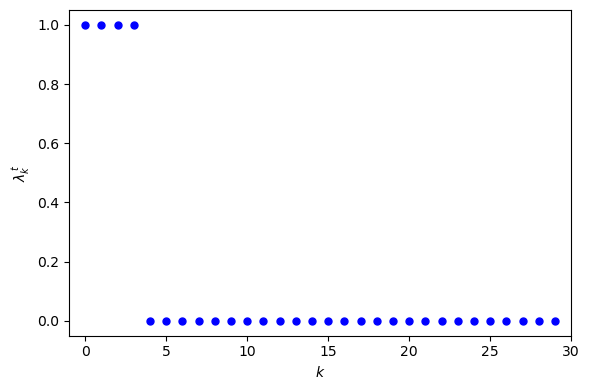

First six eigenvalues of P^500: [1.00000000e+00 1.00000000e+00 1.00000000e+00 1.00000000e+00
 1.80317641e-06 1.80250652e-06]


In [171]:
# Now, we try to reproduce the Fig. 2 (b) of the paper:

b = 1.0
M = 1000
N = 32
epsilon = 0.03
t = 500 # diffusion time

mu = np.linspace(-5 * b, 15 * b, M)
k = np.linspace(-np.pi, np.pi, N + 1)
kx, ky = np.meshgrid(k, k, indexing="ij")
dx = np.sin(kx)
dy = np.sin(ky)
mass_offset = 2*b * (2 - np.cos(kx) - np.cos(ky))

X = np.empty((M, 3 * kx.size))
for i, mu_i in enumerate(mu):
    dz = mu_i - mass_offset
    norm = np.sqrt(dx**2 + dy**2 + dz**2)
    X[i] = np.stack((dx/norm, dy/norm, dz/norm), axis=2).ravel()

#The above code is same as before

distance = squareform(pdist(X, metric="chebyshev"))
K = np.exp(-distance ** 2 / (4 * epsilon))
P = K / K.sum(axis=1, keepdims=True)
lambda_P = eigvals(P)
lambda_t = np.sort(np.abs(lambda_P))[::-1][:30] ** t  

#let us plot now
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(np.arange(30), lambda_t, "o", color="blue", markersize=5)
ax.set(xlabel=r"$k$", ylabel=r"$\lambda_k^{\,t}$", xlim=(-1, 30), ylim=(-0.05, 1.05))
ax.set_xticks(np.arange(0, 31, 5))
plt.tight_layout()
plt.show()

print("First six eigenvalues of P^500:", lambda_t[:6])

## Let's check the Euclidean case

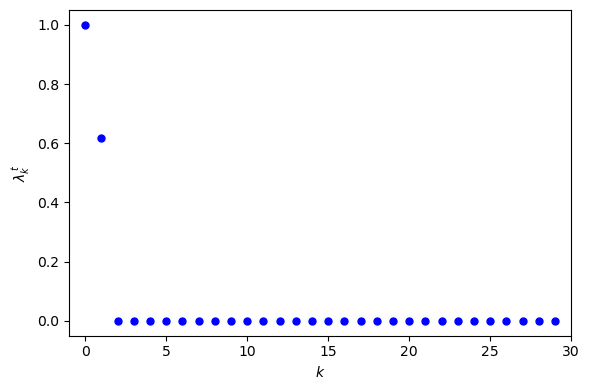

First six eigenvalues of P^500: [1.00000000e+00 6.17419361e-01 1.17889132e-08 3.11939061e-16
 1.51157725e-46 2.12621499e-68]


In [179]:
# Now, we try to reproduce the Fig. 2 (b) of the paper:

b = 1.0
M = 1000
N = 32
epsilon = 2e-5
t = 500 # diffusion time

mu = np.linspace(-5 * b, 15 * b, M)
k = np.linspace(-np.pi, np.pi, N + 1)
kx, ky = np.meshgrid(k, k, indexing="ij")
dx = np.sin(kx)
dy = np.sin(ky)
mass_offset = 2*b * (2 - np.cos(kx) - np.cos(ky))

X = np.empty((M, 3 * kx.size))
for i, mu_i in enumerate(mu):
    dz = mu_i - mass_offset
    norm = np.sqrt(dx**2 + dy**2 + dz**2)
    X[i] = np.stack((dx/norm, dy/norm, dz/norm), axis=2).ravel()

#The above code is same as before

distance = squareform(pdist(X, metric="euclidean"))
K = np.exp(-distance**2 / (4 * epsilon * (N + 1)**4))

P = K / K.sum(axis=1, keepdims=True)
lambda_P = eigvals(P)
lambda_t = np.sort(np.abs(lambda_P))[::-1][:30] ** t 

#let us plot now
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(np.arange(30), lambda_t, "o", color="blue", markersize=5)
ax.set(xlabel=r"$k$", ylabel=r"$\lambda_k^{\,t}$", xlim=(-1, 30), ylim=(-0.05, 1.05))
ax.set_xticks(np.arange(0, 31, 5))
plt.tight_layout()
plt.show()

print("First six eigenvalues of P^500:", lambda_t[:6])

## Effect of increasing $\epsilon$
![](<Minimal cluster count curve diagram.png>)